<a href="https://colab.research.google.com/github/Aabid-A/test/blob/master/IB9HP0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sqlite3
import pandas as pd

In [2]:
conn = sqlite3.connect("hospital.db")
cur = conn.cursor()

In [6]:
# Create the tables using SQLite
# Can edit table names/items as we go

cur.executescript("""
CREATE TABLE IF NOT EXISTS patient (
    patient_id INTEGER PRIMARY KEY,
    first_name TEXT NOT NULL,
    last_name TEXT NOT NULL,
    dob DATE NOT NULL,
    sex TEXT,
    phone TEXT,
    email TEXT,
    register_date DATE NOT NULL
);

CREATE TABLE IF NOT EXISTS department (
    dept_id INTEGER PRIMARY KEY,
    dept_name TEXT NOT NULL UNIQUE,
    location TEXT
);

CREATE TABLE IF NOT EXISTS doctor (
    doctor_id INTEGER PRIMARY KEY,
    dept_id INTEGER,
    first_name TEXT NOT NULL,
    last_name TEXT NOT NULL,
    title TEXT,
    specialty TEXT,
    email TEXT,
    is_active INTEGER NOT NULL CHECK (is_active IN (0, 1)),
    FOREIGN KEY (dept_id) REFERENCES department(dept_id)
);

CREATE TABLE IF NOT EXISTS appointment (
    appt_id INTEGER PRIMARY KEY,
    patient_id INTEGER,
    doctor_id INTEGER,
    appt_datetime TEXT NOT NULL,
    channel TEXT,
    status TEXT NOT NULL CHECK (status IN ('Scheduled', 'Completed', 'No show', 'Cancelled')),
    created_time TEXT,
    FOREIGN KEY (patient_id) REFERENCES patient(patient_id),
    FOREIGN KEY (doctor_id) REFERENCES doctor(doctor_id)
);

CREATE TABLE IF NOT EXISTS encounter (
  encounter_id INTEGER PRIMARY KEY,
  patient_id INTEGER,
  doctor_id INTEGER,
  dept_id INTEGER,
  appt_id INTEGER,
  checkin_time TEXT,
  start_time TEXT,
  end_time TEXT,
  FOREIGN KEY (patient_id) REFERENCES patient(patient_id),
  FOREIGN KEY (doctor_id) REFERENCES doctor(doctor_id),
  FOREIGN KEY (dept_id) REFERENCES department(dept_id),
  FOREIGN KEY (appt_id) REFERENCES appointment(appt_id)
);

CREATE TABLE IF NOT EXISTS testcatalog (
  test_id INTEGER PRIMARY KEY,
  test_name TEXT NOT NULL,
  test_category TEXT,
  standard_price REAL NOT NULL CHECK (standard_price >= 0),
  is_active INTEGER NOT NULL CHECK (is_active IN (0, 1)) DEFAULT 1
);

CREATE TABLE IF NOT EXISTS labtestorder (
  lab_order_id INTEGER PRIMARY KEY,
  encounter_id INTEGER,
  test_id INTEGER,
  order_time TEXT,
  results_time TEXT,
  status TEXT NOT NULL CHECK (status IN ('Ordered', 'Collected', 'Resulted', 'Cancelled')),
  FOREIGN KEY (encounter_id) REFERENCES encounter(encounter_id),
  FOREIGN KEY (test_id) REFERENCES testcatalog(test_id)
);

CREATE TABLE IF NOT EXISTS invoice (
  invoice_id INTEGER PRIMARY KEY,
  encounter_id INTEGER,
  issue_time TEXT,
  total_amount REAL NOT NULL CHECK (total_amount >= 0),
  status TEXT NOT NULL CHECK (status IN ('Open', 'Partially Paid', 'Paid', 'Void')),
  FOREIGN KEY (encounter_id) REFERENCES encounter(encounter_id)
);

CREATE TABLE IF NOT EXISTS payment (
  payment_id INTEGER PRIMARY KEY,
  invoice_id INTEGER,
  pay_time TEXT,
  method TEXT,
  amount REAL NOT NULL CHECK (amount >= 0),
  FOREIGN KEY (invoice_id) REFERENCES invoice(invoice_id)
);

""")

conn.commit()
print("All tables created.")

All tables created.


In [4]:
!apt-get install -y graphviz libgraphviz-dev
!pip install eralchemy2

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-6ubuntu0.1).
The following additional packages will be installed:
  libatk1.0-0 libatk1.0-data libgail-common libgail18 libgtk2.0-0
  libgtk2.0-bin libgtk2.0-common libgvc6-plugins-gtk librsvg2-common
  libxcomposite1 libxdot4
Suggested packages:
  gvfs
The following NEW packages will be installed:
  libatk1.0-0 libatk1.0-data libgail-common libgail18 libgraphviz-dev
  libgtk2.0-0 libgtk2.0-bin libgtk2.0-common libgvc6-plugins-gtk
  librsvg2-common libxcomposite1 libxdot4
0 upgraded, 12 newly installed, 0 to remove and 2 not upgraded.
Need to get 2,496 kB of archives.
After this operation, 7,963 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 libatk1.0-data all 2.36.0-3build1 [2,824 B]
Get:2 http://archive.ubuntu.com/ubuntu jammy/main amd64 libatk1.0-0 amd64 2.36.0-3build1 [51.9 kB]
Get:3 http:/

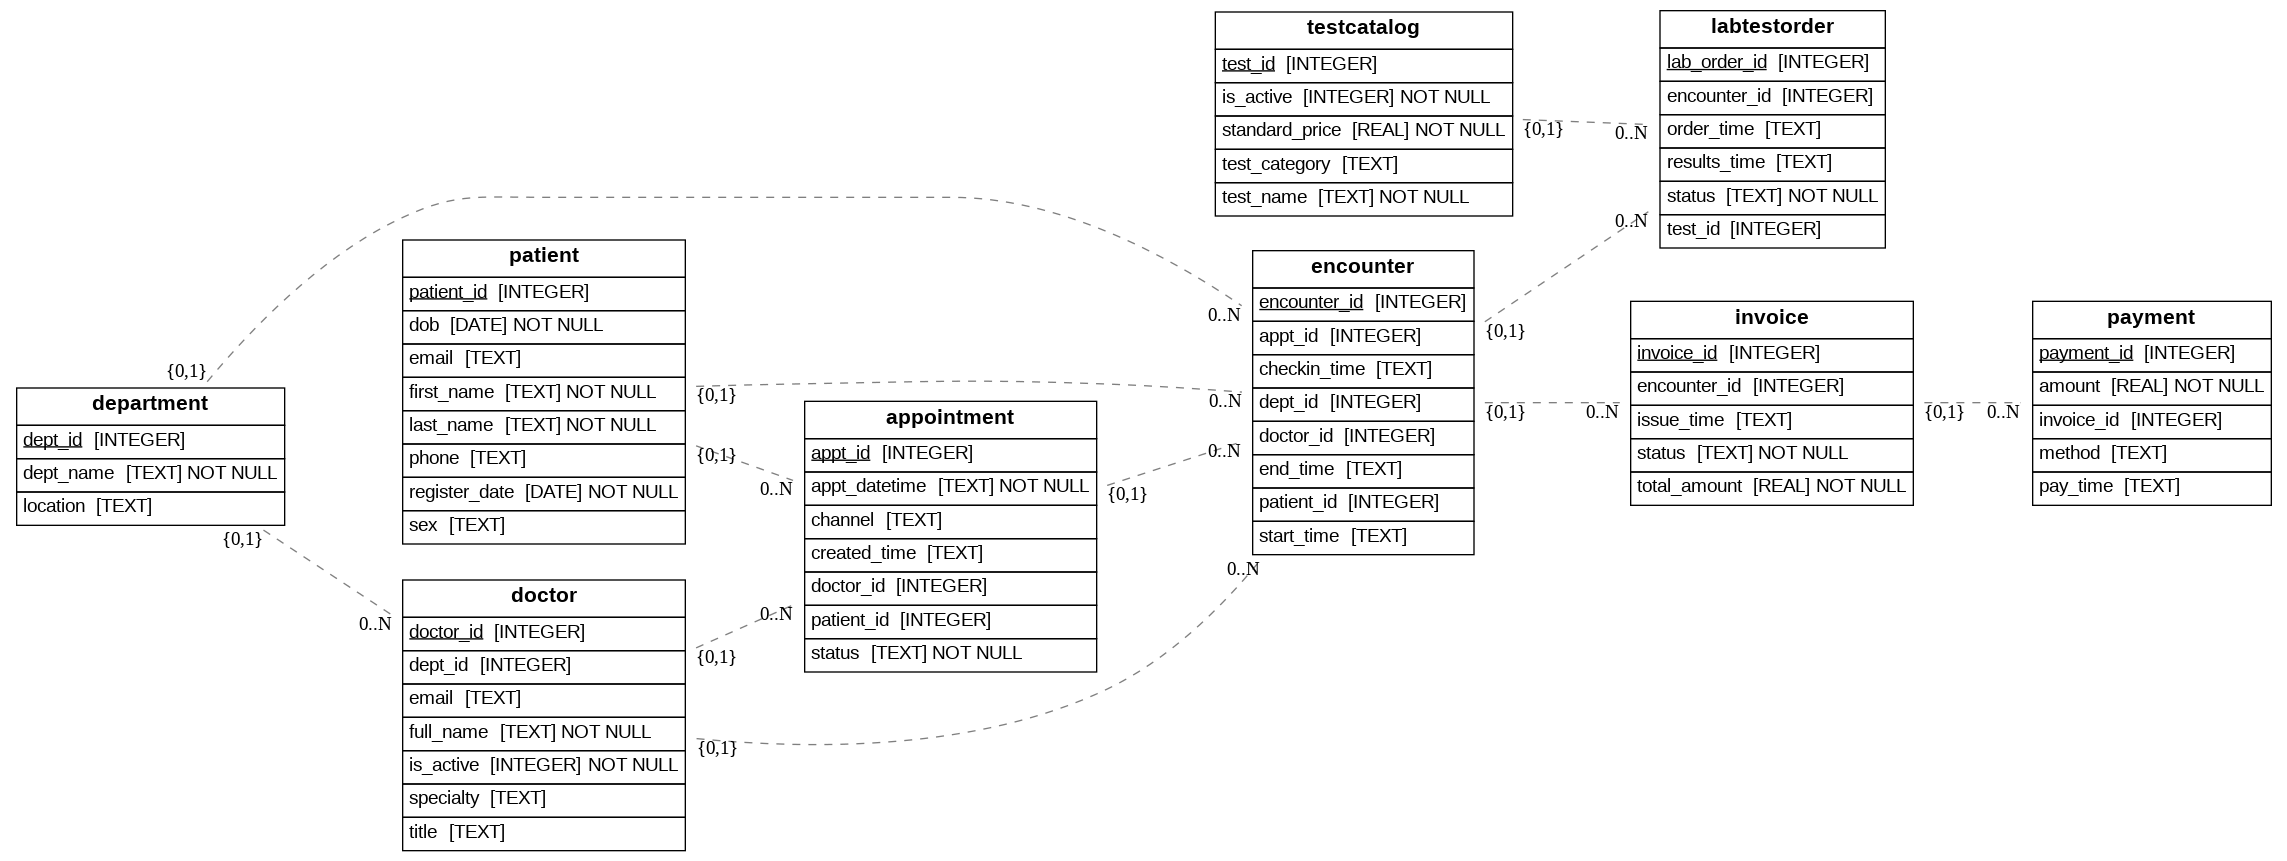

In [7]:
from eralchemy2 import render_er
from IPython.display import Image

render_er("sqlite:///hospital.db", "schema_diagram.png")
Image("schema_diagram.png")